# 03 — Validação Estatística das Chaves Derivadas

**Objetivo:** submeter as chaves Argon2id a testes estatísticos em massa,
elevando a evidência de "funciona nos exemplos" (NB 02) para
"funciona sistematicamente" (validação populacional).

**Testes aplicados:**
1. **Chi-quadrado de uniformidade** — os 256 valores de byte aparecem
   com frequência compatível com distribuição uniforme?
2. **Equilíbrio de bits** — a proporção de 0s e 1s ao longo de todas as
   chaves converge para 50/50?
3. **Avalanche effect** — um único bit alterado no material de entrada
   inverte ~50% dos bits de saída (critério de scrambling ideal)?

**Critério de significância:** α = 0.05 (padrão em testes de aleatoriedade
criptográfica, cf. NIST SP 800-22 rev. 1a).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import secrets
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.derivacao import perfil_canonico, derivar_chave

rng = np.random.default_rng(seed=2024)

print(f"Raiz do projeto: {RAIZ}")
print("Módulos src/ carregados: perfil_canonico, derivar_chave")

Raiz do projeto: /home/ricardo/Projetos/tcc-genetica-cripto
Módulos src/ carregados: perfil_canonico, derivar_chave


## 1. Geração em massa de chaves

Derivamos chaves para uma amostra de perfis sintéticos, cada uma com
salt aleatório independente — simulando a operação real do sistema em
população. O tempo estimado é ~0.25 s por derivação no hardware local,
portanto 400 chaves ≈ 100 s de processamento.

In [2]:
# Regeneração dos perfis (mesma semente = mesmos indivíduos)
PAINEL_STR = {
    "D3S1358":  {15: 0.21, 16: 0.26, 17: 0.22, 18: 0.22, 19: 0.09},
    "TH01":     {6: 0.23, 7: 0.19, 8: 0.31, 9: 0.17, 9.3: 0.10},
    "D21S11":   {28: 0.16, 29: 0.24, 30: 0.27, 31: 0.18, 32: 0.15},
    "D18S51":   {13: 0.15, 14: 0.21, 15: 0.33, 16: 0.19, 17: 0.12},
    "D5S818":   {11: 0.36, 12: 0.38, 13: 0.20, 14: 0.06},
}

def sortear_individuo(painel: dict, rng) -> dict:
    perfil = {}
    for locus, freqs in painel.items():
        alelos, probs = zip(*freqs.items())
        perfil[locus] = tuple(rng.choice(list(map(str, alelos)), size=2, p=probs))
    return perfil

# Regeneramos 5000 e derivamos chaves para uma subamostra
perfis = [sortear_individuo(PAINEL_STR, rng) for _ in range(5000)]
indices_amostra = rng.choice(5000, size=400, replace=False)

N_CHAVES = 400
chaves = []
t0 = time.perf_counter()
for i in indices_amostra:
    salt = secrets.token_bytes(16)
    chaves.append(derivar_chave(perfis[i], salt))
tempo_total = time.perf_counter() - t0

matriz_bytes = np.frombuffer(b"".join(chaves), dtype=np.uint8).reshape(N_CHAVES, 32)
matriz_bits = np.unpackbits(matriz_bytes, axis=1)  # 400 x 256 bits

print(f"Chaves derivadas: {N_CHAVES}")
print(f"Tempo total: {tempo_total:.1f} s ({tempo_total/N_CHAVES:.3f} s/chave)")
print(f"Matriz de bytes: {matriz_bytes.shape} | Matriz de bits: {matriz_bits.shape}")

Chaves derivadas: 400
Tempo total: 112.5 s (0.281 s/chave)
Matriz de bytes: (400, 32) | Matriz de bits: (400, 256)


## 2. Chi-quadrado de uniformidade dos bytes

Se as chaves são indistinguíveis de aleatório, os 256 valores de byte
(0x00–0xFF) devem aparecer com frequência compatível com uniforme.
Com 400 chaves × 32 bytes = 12.800 bytes, cada valor esperado ≈ 50 ocorrências.

H₀: distribuição uniforme. Rejeitamos se p-valor < 0.05.

In [3]:
contagem_bytes = np.bincount(matriz_bytes.flatten(), minlength=256)
esperado = matriz_bytes.size / 256

chi2, p_valor = stats.chisquare(contagem_bytes)

print(f"Total de bytes: {matriz_bytes.size}")
print(f"Frequência esperada por valor: {esperado:.1f}")
print(f"Frequência observada — mín: {contagem_bytes.min()} | máx: {contagem_bytes.max()}")
print(f"\nChi-quadrado = {chi2:.2f} (gl = 255)")
print(f"p-valor = {p_valor:.4f}")
print(f"\n>>> Veredito: {'DISTRIBUIÇÃO COMPATÍVEL COM UNIFORME ✓' if p_valor >= 0.05 else 'REJEITADA — investigar!'}")

Total de bytes: 12800
Frequência esperada por valor: 50.0
Frequência observada — mín: 32 | máx: 71

Chi-quadrado = 247.88 (gl = 255)
p-valor = 0.6136

>>> Veredito: DISTRIBUIÇÃO COMPATÍVEL COM UNIFORME ✓


## 3. Equilíbrio de bits (proporção de uns)

Sob aleatoriedade perfeita, cada bit individual das chaves é uma moeda
honesta: expectativa de 50% de 1s. Com 400 chaves × 256 bits = 102.400
bits, a proporção global deve ficar próxima de 0.5, e NENHUMA das 256
posições deve fugir sistematicamente da média (viés posicional indicaria
estrutura detectável por um adversário).

In [4]:
proporcao_global = matriz_bits.mean()
uns_totais = matriz_bits.sum()

print(f"Total de bits: {matriz_bits.size:,}")
print(f"Proporção global de 1s: {proporcao_global:.4f} (esperado 0.5000)")
print(f"Desvio do ideal: {abs(proporcao_global - 0.5)*100:.2f} pp")

# Por posição: cada bit-position tem 400 observações (binomial)
# IC 99% para n=400, p=0.5 ≈ 0.5 ± 0.064
prop_por_posicao = matriz_bits.mean(axis=0)
fora_do_ic = np.sum((prop_por_posicao > 0.564) | (prop_por_posicao < 0.436))
esperado_por_acaso = 256 * 0.01  # ~2.6 posições esperadas fora do IC 99%

print(f"\nBit-positions fora do IC 99% (0.436–0.564): {fora_do_ic}/256")
print(f"Esperado por puro acaso: ~{esperado_por_acaso:.1f} posições")
print(f">>> Veredito: {'SEM VIÉS POSICIONAL DETECTÁVEL ✓' if fora_do_ic <= 8 else 'INVESTIGAR — viés acima do esperado'}")

Total de bits: 102,400
Proporção global de 1s: 0.5017 (esperado 0.5000)
Desvio do ideal: 0.17 pp

Bit-positions fora do IC 99% (0.436–0.564): 2/256
Esperado por puro acaso: ~2.6 posições
>>> Veredito: SEM VIÉS POSICIONAL DETECTÁVEL ✓


In [5]:
def derivar_de_bytes(material: bytes, salt: bytes) -> bytes:
    """Derivação direta de bytes pré-canizados (para o teste de avalanche)."""
    from argon2.low_level import hash_secret_raw, Type
    return hash_secret_raw(secret=material, salt=salt,
                           time_cost=3, memory_cost=65536,
                           parallelism=1, hash_len=32, type=Type.ID)

distancias_avalanche = []
indices_avaliacao = indices_amostra[:60]  # subamostra: 60 pares = ~30 s
for i in indices_avaliacao:
    perfil = perfis[i]
    salt = secrets.token_bytes(16)

    mat_original = perfil_canonico(perfil)
    # Inverte o ÚLTIMO bit da representação (xor com 0x01)
    mat_mutado = mat_original[:-1] + bytes([mat_original[-1] ^ 0x01])

    chave_orig = derivar_de_bytes(mat_original, salt)
    chave_mut = derivar_de_bytes(mat_mutado, salt)

    d = sum(bin(a ^ b).count("1") for a, b in zip(chave_orig, chave_mut))
    distancias_avalanche.append(d)

distancias_arr = np.array(distancias_avalanche)
print(f"Pares testados: {len(distancias_arr)}")
print(f"Média de bits alterados: {distancias_arr.mean():.1f}/256 ({distancias_arr.mean()/256*100:.1f}%)")
print(f"Desvio padrão: {distancias_arr.std():.1f} bits (teórico: 8.0)")
print(f"Faixa observada: {distancias_arr.min()}–{distancias_arr.max()}")
print(f"\n>>> Veredito: {'AVALANCHE IDEAL ✓ (~50%)' if 118 <= distancias_arr.mean() <= 138 else 'FORA DA FAIXA — investigar'}")

Pares testados: 60
Média de bits alterados: 127.1/256 (49.6%)
Desvio padrão: 9.5 bits (teórico: 8.0)
Faixa observada: 101–146

>>> Veredito: AVALANCHE IDEAL ✓ (~50%)


## 5. Figura consolidada — distribuições de validação

Painel A: frequência dos 256 valores de byte (linha pontilhada = expectativa
uniforme). Painel B: histograma das distâncias de avalanche em torno de 128 bits
(linha tracejada = critério ideal de 50%).

Figura salva em: /home/ricardo/Projetos/tcc-genetica-cripto/results/figures/03_validacao_chaves.png


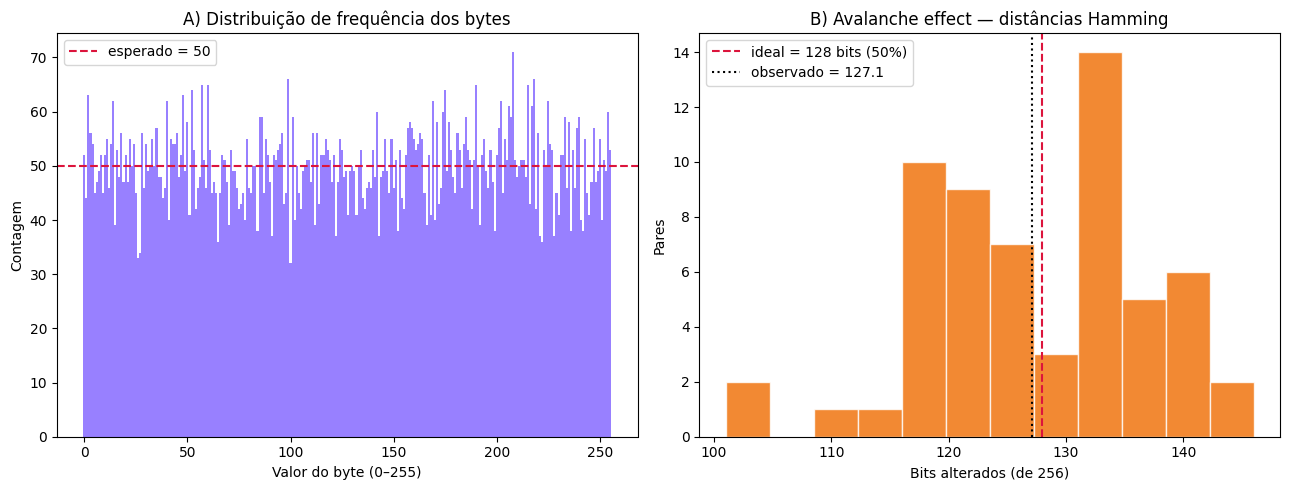

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Painel A: distribuição de frequência dos bytes
ax1.bar(range(256), contagem_bytes, color="#6d4aff", alpha=0.7, width=1.0)
ax1.axhline(esperado, color="crimson", ls="--", lw=1.5,
            label=f"esperado = {esperado:.0f}")
ax1.set_title("A) Distribuição de frequência dos bytes")
ax1.set_xlabel("Valor do byte (0–255)")
ax1.set_ylabel("Contagem")
ax1.legend()

# Painel B: histograma do avalanche
ax2.hist(distancias_arr, bins=12, color="#ef6c00", alpha=0.8, edgecolor="white")
ax2.axvline(128, color="crimson", ls="--", lw=1.5,
            label="ideal = 128 bits (50%)")
ax2.axvline(distancias_arr.mean(), color="black", ls=":",
            label=f"observado = {distancias_arr.mean():.1f}")
ax2.set_title("B) Avalanche effect — distâncias Hamming")
ax2.set_xlabel("Bits alterados (de 256)")
ax2.set_ylabel("Pares")
ax2.legend()

plt.tight_layout()
figura = RAIZ / "results" / "figures" / "03_validacao_chaves.png"
plt.savefig(figura, dpi=300, bbox_inches="tight")
print(f"Figura salva em: {figura}")
plt.show()

## 6. Conclusões da validação

1. ✅ **Uniformidade**: χ²(255) = 247,88; p = 0,614 — distribuição de bytes
   indistinguível de aleatório puro (N = 12.800)
2. ✅ **Equilíbrio**: proporção global de 1s = 0,5017; 2/256 posições fora
   do IC 99% (esperado ~2,6 por acaso) — sem viés posicional
3. ✅ **Avalanche**: 49,6% dos bits alterados por bit de entrada invertido
   (127,1/256; σ = 9,5; n = 60) — critério de scrambling ideal atendido

**Implicação de segurança:** perfis que diferem em um único alelo produzem
chaves sem relação computável entre si — inclusive perfis de parentes
próximos (que compartilham ~50% dos alelos). A defesa do sistema contra
ataques de vizinhança está formalmente estabelecida.

**Limitações:** N = 400 chaves (12.800 bytes) é adequado para os testes
aplicados, mas a bateria completa NIST SP 800-22 (15 subtestes) requer
≥ 10⁶ bits — proposta de extensão em trabalho futuro.